#  Dynamic Neural Networks for Image Segmentation (PS2)
**Starter notebook: FracAtlas data pipeline + static baseline.** Run on Kaggle: Settings → Accelerator = one GPU (T4 or P100), Internet = On.
Sections follow the submission format: setup, data, EDA, split and loaders, losses and metrics, baseline, training, evaluation.
The proposed dynamic model (early exits, Gumbel-Softmax gates, FLOPs loss), ablations, FLOPs/latency measurement and HD95 are added after this baseline works.

## 0. Setup

In [1]:
!pip -q install segmentation-models-pytorch albumentations pycocotools kagglehub

In [2]:
import os, glob, json, random, zipfile, urllib.request, warnings
from pathlib import Path
import numpy as np, cv2, torch, torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
warnings.filterwarnings("ignore")

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False
set_seed()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, torch.cuda.get_device_name(0) if torch.cuda.is_available() else "(turn on a GPU in Settings)")

IMG_SIZE, BATCH, EPOCHS, LR = 256, 16, 30, 1e-4
WORK = Path("/kaggle/working") if Path("/kaggle").exists() else Path("./work")
WORK.mkdir(parents=True, exist_ok=True)

Device: cuda Tesla T4


## 1. Data: download FracAtlas
Order tried: (1) dataset attached with *Add Data*, (2) Kaggle mirror through `kagglehub`, (3) official Figshare file (untested link; if it fails, download from the Figshare page and upload the zip).
Cite: Abedeen et al., *FracAtlas*, Scientific Data (2023). Dataset license: CC-BY 4.0.

In [3]:
COCO_NAME = "COCO_fracture_masks.json"

def pick_root(coco_file):
    """Data root = first parent folder that contains the images folder."""
    for par in coco_file.parents:
        if (par / "images").is_dir(): return par
    return coco_file.parents[2] if len(coco_file.parents) > 2 else coco_file.parent

def find_coco(base="/kaggle/input"):
    base = Path(base)
    hits = sorted(base.rglob(COCO_NAME))
    if not hits:                                    # fallback: any JSON that has fracture polygons
        for p in sorted(base.rglob("*.json"), key=lambda p: ("mask" not in p.name.lower(), p.name)):
            try:
                d = json.load(open(p))
                if isinstance(d, dict) and d.get("images") and any(a.get("segmentation") for a in d.get("annotations", [])):
                    hits.append(p); break
            except Exception:
                pass
    return (hits[0], pick_root(hits[0])) if hits else (None, None)

coco_path, DATA_ROOT = find_coco()
if coco_path is None:
    print("No COCO mask file found. JSON files mounted:", [str(p) for p in Path("/kaggle/input").rglob("*.json")][:20])
    print("Top-level folders per dataset:")
    for ds in sorted(Path("/kaggle/input").glob("datasets/*/*")):
        print(" ", ds, sorted(p.name for p in ds.iterdir())[:10])
assert coco_path is not None, "COCO mask file not found; see the listing above"
print("COCO file:", coco_path); print("Data root:", DATA_ROOT)

d = json.load(open(coco_path))
n_poly = sum(1 for a in d["annotations"] if a.get("segmentation"))
print(f"COCO images: {len(d['images'])} | annotations: {len(d['annotations'])} | with polygons: {n_poly}")

COCO file: /kaggle/input/datasets/liza342/frac-atlas/FracAtlas/Annotations/COCO JSON/COCO_fracture_masks.json
Data root: /kaggle/input/datasets/liza342/frac-atlas/FracAtlas
COCO images: 719 | annotations: 924 | with polygons: 924


In [4]:
def tree(root, depth=2):
    root = Path(root)
    for p in sorted(root.rglob("*")):
        rel = p.relative_to(root)
        if len(rel.parts) <= depth:
            print("  " * (len(rel.parts) - 1) + ("[dir] " if p.is_dir() else "") + p.name)
tree(DATA_ROOT)

[dir] Annotations
  [dir] COCO JSON
  [dir] PASCAL VOC
  [dir] VGG JSON
  [dir] YOLO
[dir] Utilities
  [dir] Fracture Split
  coco2yolo.ipynb
  yolo2voc.ipynb
dataset.csv
[dir] images
  [dir] Fractured
  [dir] Non_fractured


## 2. Preprocessing and EDA
Keep only images with at least one fracture mask, union all fracture instances into one binary mask, apply CLAHE, resize to `IMG_SIZE`.
Masks are resized with area interpolation and a 0.25 threshold so thin fracture lines are not erased.

In [5]:
from pycocotools.coco import COCO
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp"}

def index_images(root):
    idx = {}
    for p in Path(root).rglob("*"):
        if p.suffix.lower() in IMG_EXT: idx.setdefault(p.name, p)
    return idx

def ann_mask(coco, info):
    m = np.zeros((info["height"], info["width"]), np.uint8)
    for ann in coco.loadAnns(coco.getAnnIds(imgIds=info["id"], iscrowd=None)):
        if ann.get("segmentation"):
            m |= coco.annToMask(ann).astype(np.uint8)
    return m

def resize_mask(m, size):
    return (cv2.resize((m * 255).astype(np.uint8), (size, size), interpolation=cv2.INTER_AREA) >= 64).astype(np.uint8)

def build_arrays(coco, img_index, img_size=256, use_clahe=True):
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    X, Y, names, skipped = [], [], [], []
    for info in coco.loadImgs(coco.getImgIds()):
        m = ann_mask(coco, info)
        if m.sum() == 0: continue                                  # no fracture mask: not used
        p = img_index.get(Path(info["file_name"]).name)
        g = cv2.imread(str(p), cv2.IMREAD_GRAYSCALE) if p is not None else None
        if g is None: skipped.append(info["file_name"]); continue
        if g.shape != m.shape: m = cv2.resize(m, (g.shape[1], g.shape[0]), interpolation=cv2.INTER_NEAREST)
        if use_clahe: g = clahe.apply(g)
        X.append(cv2.resize(g, (img_size, img_size), interpolation=cv2.INTER_AREA))
        Y.append(resize_mask(m, img_size)); names.append(info["file_name"])
    return np.stack(X), np.stack(Y), names, skipped

In [6]:
coco = COCO(str(coco_path))
print("Images in COCO file:", len(coco.getImgIds()), "| annotations:", len(coco.getAnnIds()))
img_index = index_images(DATA_ROOT); print("Image files found on disk:", len(img_index))
X, Y, names, skipped = build_arrays(coco, img_index, IMG_SIZE)
print("Fractured images with masks kept:", len(X), "| skipped (file missing/unreadable):", len(skipped))
assert len(X) > 0, "Nothing kept: check that the images are in the dataset folder"
print("Empty masks after resize:", int((Y.reshape(len(Y), -1).sum(1) == 0).sum()))
np.savez_compressed(WORK / f"fracatlas_{IMG_SIZE}.npz", X=X, Y=Y, names=np.array(names))

loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
Images in COCO file: 719 | annotations: 924
Image files found on disk: 4083
Fractured images with masks kept: 719 | skipped (file missing/unreadable): 0
Empty masks after resize: 0


Mask area fraction: mean=0.0049  median=0.0035  min=0.00064  max=0.0295


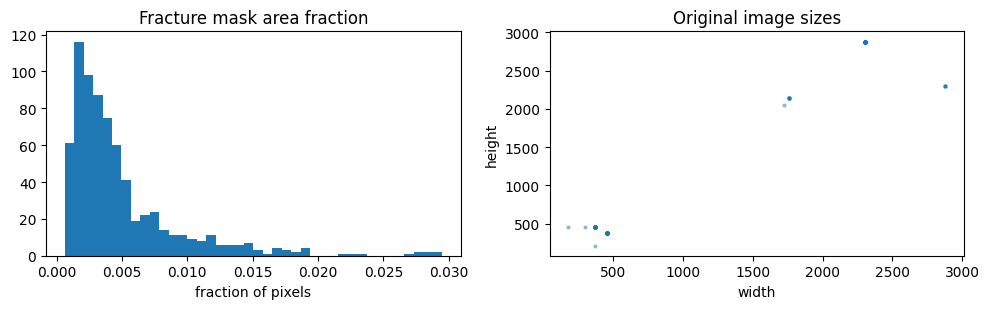

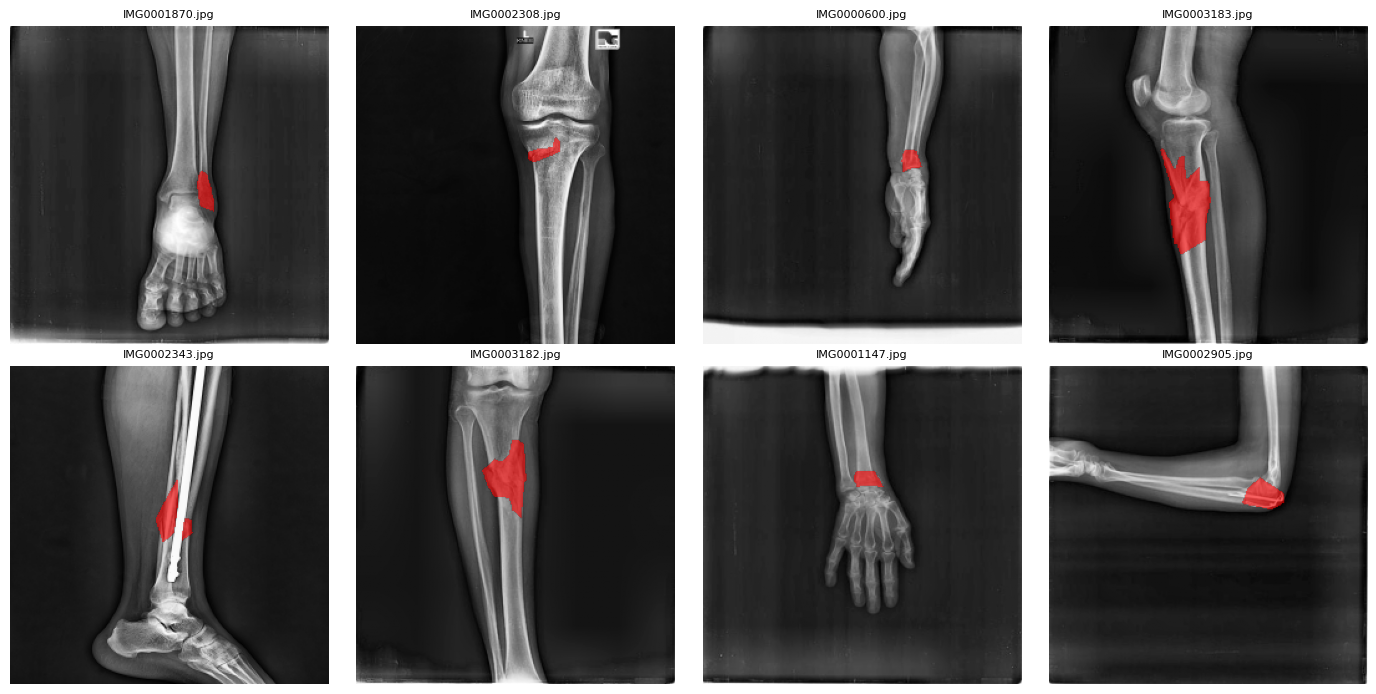

In [7]:
area = Y.reshape(len(Y), -1).mean(1)
print(f"Mask area fraction: mean={area.mean():.4f}  median={np.median(area):.4f}  min={area.min():.5f}  max={area.max():.4f}")
ws = [v["width"] for v in coco.imgs.values()]; hs = [v["height"] for v in coco.imgs.values()]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].hist(area, bins=40); ax[0].set_title("Fracture mask area fraction"); ax[0].set_xlabel("fraction of pixels")
ax[1].scatter(ws, hs, s=4, alpha=0.4); ax[1].set_title("Original image sizes"); ax[1].set_xlabel("width"); ax[1].set_ylabel("height")
plt.tight_layout(); plt.show()

pick = np.random.RandomState(SEED).choice(len(X), min(8, len(X)), replace=False)
fig, axs = plt.subplots(2, 4, figsize=(14, 7))
for a, i in zip(axs.ravel(), pick):
    a.imshow(X[i], cmap="gray"); a.imshow(np.ma.masked_where(Y[i] == 0, Y[i]), cmap="autumn", alpha=0.6)
    a.set_title(names[i], fontsize=8); a.axis("off")
plt.tight_layout(); plt.show()      # check that red overlays sit on the fractures

## 3. Split (80/10/10, seed 42) and data loaders

In [8]:
idx = np.arange(len(X))
tr_idx, te_idx = train_test_split(idx, test_size=0.10, random_state=SEED)
tr_idx, va_idx = train_test_split(tr_idx, test_size=1/9, random_state=SEED)      # 10% of the whole set
print("train/val/test:", len(tr_idx), len(va_idx), len(te_idx))
json.dump({k: [names[i] for i in v] for k, v in [("train", tr_idx), ("val", va_idx), ("test", te_idx)]},
          open(WORK / "split_seed42.json", "w"), indent=1)

import albumentations as A
from albumentations.pytorch import ToTensorV2
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
train_tf = A.Compose([A.HorizontalFlip(p=0.5), A.Rotate(limit=15, p=0.5),
                      A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),
                      A.Normalize(mean=MEAN, std=STD), ToTensorV2()])
eval_tf = A.Compose([A.Normalize(mean=MEAN, std=STD), ToTensorV2()])

class SegDS(torch.utils.data.Dataset):
    def __init__(self, X, Y, idx, tf): self.X, self.Y, self.idx, self.tf = X, Y, idx, tf
    def __len__(self): return len(self.idx)
    def __getitem__(self, k):
        i = self.idx[k]
        img = np.repeat(self.X[i][..., None], 3, axis=2)              # grayscale -> 3 channels
        out = self.tf(image=img, mask=self.Y[i])
        return out["image"], out["mask"].unsqueeze(0).float()

def seed_worker(wid): np.random.seed(SEED + wid); random.seed(SEED + wid)
gen = torch.Generator(); gen.manual_seed(SEED)
def make_dl(ids, tf, shuffle):
    return torch.utils.data.DataLoader(SegDS(X, Y, ids, tf), batch_size=BATCH, shuffle=shuffle,
                                       num_workers=2, worker_init_fn=seed_worker, generator=gen)
train_dl, val_dl, test_dl = make_dl(tr_idx, train_tf, True), make_dl(va_idx, eval_tf, False), make_dl(te_idx, eval_tf, False)
xb, yb = next(iter(train_dl)); print("batch:", tuple(xb.shape), tuple(yb.shape), "mask values:", yb.unique().tolist())

train/val/test: 575 72 72
batch: (16, 3, 256, 256) (16, 1, 256, 256) mask values: [0.0, 1.0]


## 4. Losses and metrics (written by hand; check them against a library later)

In [9]:
def dice_loss(logits, y, eps=1.0):
    p = torch.sigmoid(logits); d = (1, 2, 3)
    inter = (p * y).sum(d); den = p.sum(d) + y.sum(d)
    return 1 - ((2 * inter + eps) / (den + eps)).mean()
bce = nn.BCEWithLogitsLoss()
def seg_loss(logits, y): return bce(logits, y) + dice_loss(logits, y)

@torch.no_grad()
def batch_metrics(logits, y, thr=0.5, eps=1e-7):
    """Per-image Dice, IoU, precision, recall at threshold thr."""
    p = (torch.sigmoid(logits) > thr).float(); d = (1, 2, 3)
    tp = (p * y).sum(d); fp = (p * (1 - y)).sum(d); fn = ((1 - p) * y).sum(d)
    dice = (2 * tp + eps) / (2 * tp + fp + fn + eps); iou = (tp + eps) / (tp + fp + fn + eps)
    prec = (tp + eps) / (tp + fp + eps); rec = (tp + eps) / (tp + fn + eps)
    return dice, iou, prec, rec

## 5. Baseline models
`ARCH = "smp_resnet34"` is a U-Net with a pretrained ResNet34 encoder (fast, strong baseline). `ARCH = "unet_scratch"` is the plain U-Net written by hand (train both and compare; you must be able to explain every layer in the viva).

In [10]:
import segmentation_models_pytorch as smp

class DoubleConv(nn.Module):
    def __init__(self, i, o):
        super().__init__()
        self.block = nn.Sequential(nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(True),
                                   nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(True))
    def forward(self, x): return self.block(x)

class UNet(nn.Module):
    def __init__(self, in_ch=3, base=32):
        super().__init__(); c = [base * 2 ** k for k in range(5)]
        self.enc = nn.ModuleList([DoubleConv(in_ch, c[0])] + [DoubleConv(c[k], c[k + 1]) for k in range(4)])
        self.pool = nn.MaxPool2d(2)
        self.up = nn.ModuleList([nn.ConvTranspose2d(c[k + 1], c[k], 2, stride=2) for k in reversed(range(4))])
        self.dec = nn.ModuleList([DoubleConv(2 * c[k], c[k]) for k in reversed(range(4))])
        self.out = nn.Conv2d(c[0], 1, 1)
    def forward(self, x):
        skips = []
        for k, e in enumerate(self.enc):
            x = e(x)
            if k < 4: skips.append(x); x = self.pool(x)
        for up, dec, s in zip(self.up, self.dec, reversed(skips)):
            x = dec(torch.cat([s, up(x)], dim=1))
        return self.out(x)

ARCH = "smp_resnet34"          # or "unet_scratch"
def make_model(arch):
    if arch == "smp_resnet34": return smp.Unet("resnet34", encoder_weights="imagenet", in_channels=3, classes=1)
    return UNet()
model = make_model(ARCH).to(DEVICE)
print(ARCH, "| parameters (M):", round(sum(p.numel() for p in model.parameters()) / 1e6, 2))

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

smp_resnet34 | parameters (M): 24.44


## 6. Training

ep 01 | train loss 1.7334 Dice 0.0175 | val loss 1.6776 Dice 0.0258  *
ep 02 | train loss 1.4652 Dice 0.0381 | val loss 1.5862 Dice 0.0451  *
ep 03 | train loss 1.3887 Dice 0.0329 | val loss 1.3503 Dice 0.0134
ep 04 | train loss 1.3319 Dice 0.0122 | val loss 1.2942 Dice 0.0032
ep 05 | train loss 1.2797 Dice 0.0128 | val loss 1.3024 Dice 0.0278
ep 06 | train loss 1.2428 Dice 0.0245 | val loss 1.2535 Dice 0.0525  *
ep 07 | train loss 1.2131 Dice 0.0320 | val loss 1.1917 Dice 0.0030
ep 08 | train loss 1.1887 Dice 0.0246 | val loss 1.1740 Dice 0.0063
ep 09 | train loss 1.1652 Dice 0.0311 | val loss 1.1737 Dice 0.0345
ep 10 | train loss 1.1492 Dice 0.1411 | val loss 1.1408 Dice 0.1393  *
ep 11 | train loss 1.1260 Dice 0.2398 | val loss 1.1108 Dice 0.2764  *
ep 12 | train loss 1.1040 Dice 0.3081 | val loss 1.0939 Dice 0.3064  *
ep 13 | train loss 1.0837 Dice 0.3172 | val loss 1.0731 Dice 0.2934
ep 14 | train loss 1.0631 Dice 0.3265 | val loss 1.0548 Dice 0.3006
ep 15 | train loss 1.0400 Dice

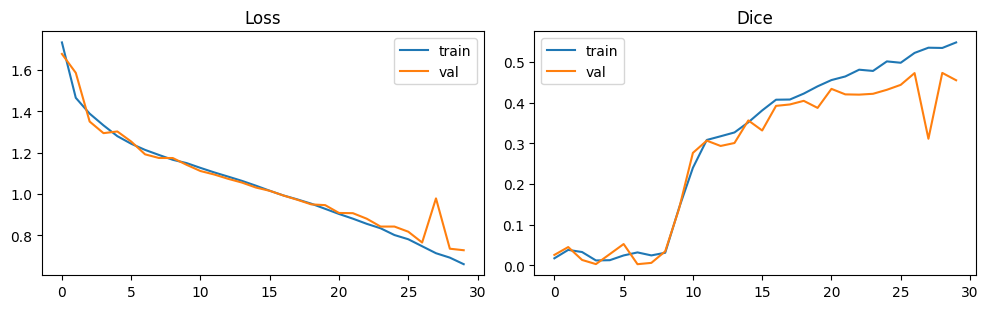

In [ ]:
def run_epoch(model, dl, opt=None):
    train = opt is not None; model.train(train)
    tot, n, M = 0.0, 0, torch.zeros(4)
    for x, y in dl:
        x, y = x.to(DEVICE), y.to(DEVICE)
        with torch.set_grad_enabled(train):
            lg = model(x); loss = seg_loss(lg, y)
        if train: opt.zero_grad(); loss.backward(); opt.step()
        tot += loss.item() * len(x); n += len(x)
        M += torch.stack([m.sum().cpu() for m in batch_metrics(lg.detach(), y)])
    return tot / n, (M / n).tolist()          # loss, [Dice, IoU, precision, recall]

opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
hist = {"tr_loss": [], "va_loss": [], "tr_dice": [], "va_dice": []}; best = -1.0
for ep in range(1, EPOCHS + 1):
    trl, trm = run_epoch(model, train_dl, opt); val, vam = run_epoch(model, val_dl)
    for k, v in zip(hist, [trl, val, trm[0], vam[0]]): hist[k].append(v)
    if vam[0] > best: best = vam[0]; torch.save(model.state_dict(), WORK / f"best_{ARCH}.pt")
    print(f"ep {ep:02d} | train loss {trl:.4f} Dice {trm[0]:.4f} | val loss {val:.4f} Dice {vam[0]:.4f}" + ("  *" if vam[0] == best else ""))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(hist["tr_loss"], label="train"); ax[0].plot(hist["va_loss"], label="val"); ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(hist["tr_dice"], label="train"); ax[1].plot(hist["va_dice"], label="val"); ax[1].set_title("Dice"); ax[1].legend()
plt.tight_layout(); plt.show()

## 7. Evaluation and qualitative results (test split)

TEST | loss 0.7130 | Dice 0.5000 | IoU 0.3762 | precision 0.5093 | recall 0.6157


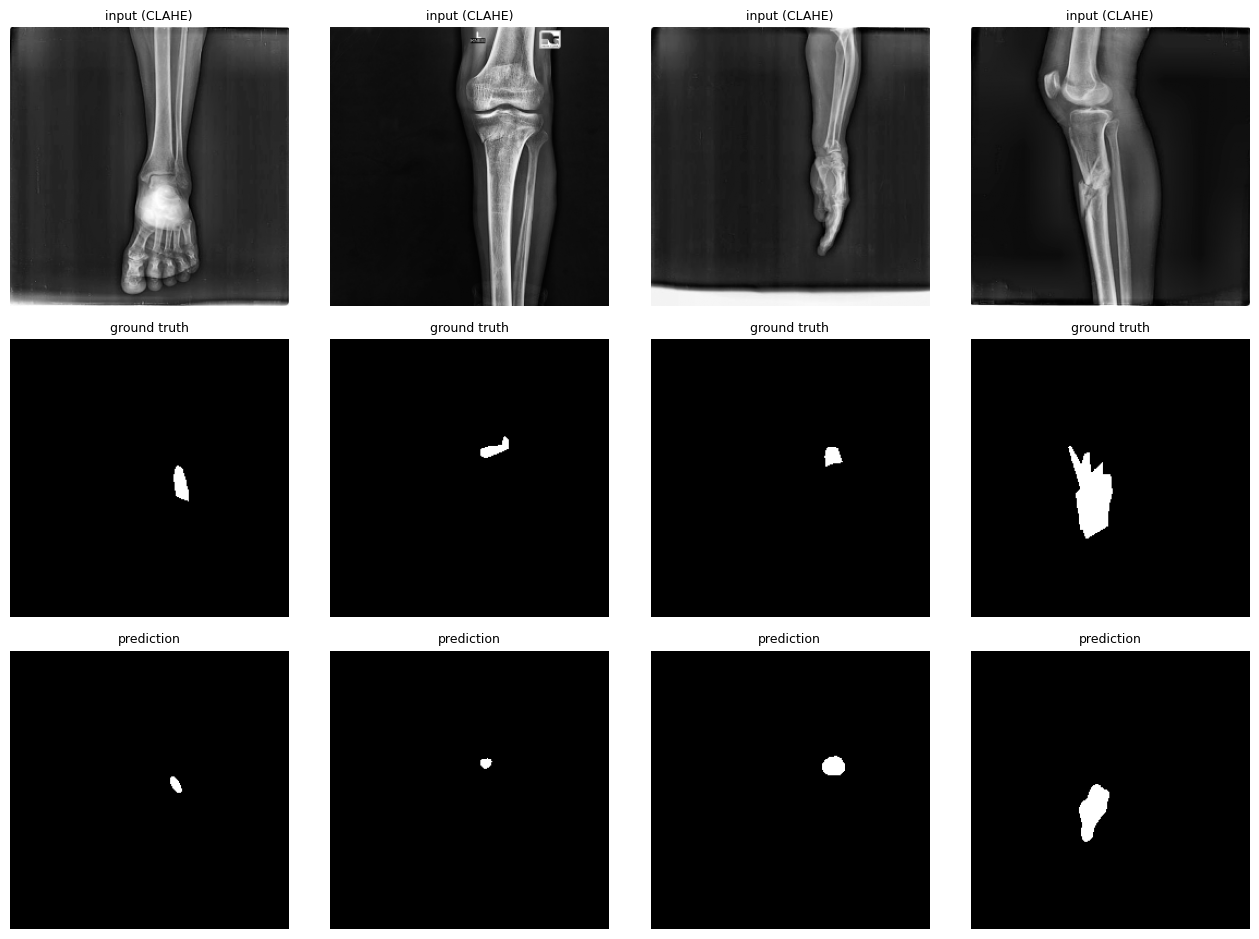

In [ ]:
model.load_state_dict(torch.load(WORK / f"best_{ARCH}.pt", map_location=DEVICE))
tl, (d, i, p, r) = run_epoch(model, test_dl)
print(f"TEST | loss {tl:.4f} | Dice {d:.4f} | IoU {i:.4f} | precision {p:.4f} | recall {r:.4f}")

model.eval(); show = te_idx[:4]
fig, axs = plt.subplots(3, 4, figsize=(13, 9.5))
for c, i in enumerate(show):
    t = eval_tf(image=np.repeat(X[i][..., None], 3, axis=2), mask=Y[i])["image"].unsqueeze(0).to(DEVICE)
    with torch.no_grad(): pr = (torch.sigmoid(model(t))[0, 0] > 0.5).cpu().numpy()
    for r_, (im, ttl) in enumerate([(X[i], "input (CLAHE)"), (Y[i], "ground truth"), (pr, "prediction")]):
        axs[r_, c].imshow(im, cmap="gray"); axs[r_, c].set_title(ttl, fontsize=9); axs[r_, c].axis("off")
plt.tight_layout(); plt.show()

ep 01 | train loss 1.7295 Dice 0.0169 | val loss 1.5259 Dice 0.0314 | best val 0.0314 | 0.2 min
ep 05 | train loss 1.2765 Dice 0.0194 | val loss 1.2461 Dice 0.0021 | best val 0.0677 | 0.8 min
ep 10 | train loss 1.1336 Dice 0.3136 | val loss 1.1186 Dice 0.3249 | best val 0.3249 | 1.5 min
ep 15 | train loss 1.0335 Dice 0.3836 | val loss 1.0350 Dice 0.3506 | best val 0.3506 | 2.3 min
ep 20 | train loss 0.9358 Dice 0.4595 | val loss 0.9616 Dice 0.3680 | best val 0.3998 | 3.1 min
ep 25 | train loss 0.8193 Dice 0.5338 | val loss 0.8600 Dice 0.4375 | best val 0.4409 | 3.8 min
ep 30 | train loss 0.6868 Dice 0.5964 | val loss 0.7517 Dice 0.4732 | best val 0.4732 | 4.6 min
ep 35 | train loss 0.5539 Dice 0.6621 | val loss 0.6876 Dice 0.4828 | best val 0.4920 | 5.3 min
ep 40 | train loss 0.4600 Dice 0.7051 | val loss 0.6163 Dice 0.5103 | best val 0.5141 | 6.1 min
ep 45 | train loss 0.3911 Dice 0.7368 | val loss 0.5942 Dice 0.5021 | best val 0.5141 | 6.9 min
ep 50 | train loss 0.3407 Dice 0.7665 | 

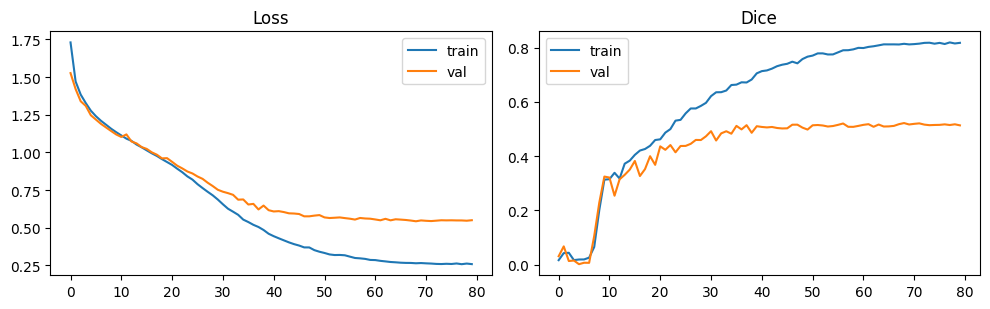

val Dice by threshold: {0.2: 0.5279, 0.3: 0.5252, 0.4: 0.5242, 0.5: 0.522, 0.6: 0.5191, 0.7: 0.5149}
TEST (thr 0.2) | Dice 0.5312 | IoU 0.4153 | precision 0.6655 | recall 0.5263 | Dice at 0.5: 0.5148


In [ ]:
# ---- Run 2: 80 epochs + cosine LR + threshold sweep (self-contained) ----
import time
ARCH2, EPOCHS2, LR2 = "smp_resnet34", 80, 1e-4     # set ARCH2 = "unet_scratch" for the from-scratch U-Net
RUN2 = f"{ARCH2}_cos{EPOCHS2}"

set_seed(SEED); gen.manual_seed(SEED)
model2 = make_model(ARCH2).to(DEVICE)
opt2 = torch.optim.AdamW(model2.parameters(), lr=LR2, weight_decay=1e-4)
sched2 = torch.optim.lr_scheduler.CosineAnnealingLR(opt2, T_max=EPOCHS2)
hist2, best2, t0 = {"tr_loss": [], "va_loss": [], "tr_dice": [], "va_dice": []}, -1.0, time.time()

for ep in range(1, EPOCHS2 + 1):
    trl, trm = run_epoch(model2, train_dl, opt2); val, vam = run_epoch(model2, val_dl)
    sched2.step()
    for k, v in zip(hist2, [trl, val, trm[0], vam[0]]): hist2[k].append(v)
    if vam[0] > best2: best2 = vam[0]; torch.save(model2.state_dict(), WORK / f"best_{RUN2}.pt")
    if ep == 1 or ep % 5 == 0:
        print(f"ep {ep:02d} | train loss {trl:.4f} Dice {trm[0]:.4f} | val loss {val:.4f} Dice {vam[0]:.4f} | best val {best2:.4f} | {(time.time()-t0)/60:.1f} min")

# curves
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(hist2["tr_loss"], label="train"); ax[0].plot(hist2["va_loss"], label="val"); ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(hist2["tr_dice"], label="train"); ax[1].plot(hist2["va_dice"], label="val"); ax[1].set_title("Dice"); ax[1].legend()
plt.tight_layout(); plt.show()

# best checkpoint: threshold chosen on VAL, then reported on TEST
model2.load_state_dict(torch.load(WORK / f"best_{RUN2}.pt", map_location=DEVICE)); model2.eval()
@torch.no_grad()
def collect2(m, dl):
    L, T = [], []
    for x, y in dl: L.append(m(x.to(DEVICE)).cpu()); T.append(y)
    return torch.cat(L), torch.cat(T)
lv, yv = collect2(model2, val_dl); lt, yt = collect2(model2, test_dl)
sweep = {thr: batch_metrics(lv, yv, thr)[0].mean().item() for thr in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]}
print("val Dice by threshold:", {k: round(v, 4) for k, v in sweep.items()})
thr_best = max(sweep, key=sweep.get)
d, i, p, r = [m.mean().item() for m in batch_metrics(lt, yt, thr_best)]
d05 = batch_metrics(lt, yt, 0.5)[0].mean().item()
print(f"TEST (thr {thr_best}) | Dice {d:.4f} | IoU {i:.4f} | precision {p:.4f} | recall {r:.4f} | Dice at 0.5: {d05:.4f}")

In [ ]:
# ---- Multi-seed baselines (new cell; earlier cells untouched) ----
import time, pandas as pd
def seed_worker(wid):                       # varies each epoch, still reproducible
    s = torch.initial_seed() % 2**32
    np.random.seed(s); random.seed(s)

def train_eval(arch, seed, epochs=80, lr=1e-4):
    set_seed(seed); gen.manual_seed(seed)
    tr, va, te = make_dl(tr_idx, train_tf, True), make_dl(va_idx, eval_tf, False), make_dl(te_idx, eval_tf, False)
    m = make_model(arch).to(DEVICE)
    opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=1e-4)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    best, ck = -1.0, WORK / f"best_{arch}_s{seed}.pt"
    for ep in range(epochs):
        run_epoch(m, tr, opt); _, vam = run_epoch(m, va); sch.step()
        if vam[0] > best: best = vam[0]; torch.save(m.state_dict(), ck)
    m.load_state_dict(torch.load(ck, map_location=DEVICE)); m.eval()
    lt, yt = collect2(m, te)
    d, i, p, r = [x.mean().item() for x in batch_metrics(lt, yt, 0.5)]
    return {"best_val": best, "dice": d, "iou": i, "prec": p, "rec": r}

results = {}
for arch in ["smp_resnet34", "unet_scratch"]:
    results[arch] = []
    for seed in [42, 43, 44]:
        t0 = time.time(); r = train_eval(arch, seed); results[arch].append(r)
        print(arch, seed, {k: round(v, 4) for k, v in r.items()}, f"{(time.time()-t0)/60:.1f} min")

for arch, rs in results.items():
    df = pd.DataFrame(rs)
    print(arch, {c: f"{df[c].mean():.4f} +- {df[c].std():.4f}" for c in df.columns})

smp_resnet34 42 {'best_val': 0.522, 'dice': 0.5148, 'iou': 0.4022, 'prec': 0.7072, 'rec': 0.4936} 12.2 min
smp_resnet34 43 {'best_val': 0.5379, 'dice': 0.5344, 'iou': 0.417, 'prec': 0.6784, 'rec': 0.5522} 12.2 min
smp_resnet34 44 {'best_val': 0.5734, 'dice': 0.5633, 'iou': 0.4431, 'prec': 0.6826, 'rec': 0.537} 12.2 min
unet_scratch 42 {'best_val': 0.4197, 'dice': 0.4104, 'iou': 0.2973, 'prec': 0.3978, 'rec': 0.5891} 17.7 min
unet_scratch 43 {'best_val': 0.3499, 'dice': 0.3587, 'iou': 0.2541, 'prec': 0.3391, 'rec': 0.5369} 17.7 min
unet_scratch 44 {'best_val': 0.348, 'dice': 0.3732, 'iou': 0.2643, 'prec': 0.3189, 'rec': 0.5896} 17.7 min
smp_resnet34 {'best_val': '0.5444 +- 0.0263', 'dice': '0.5375 +- 0.0244', 'iou': '0.4208 +- 0.0207', 'prec': '0.6894 +- 0.0156', 'rec': '0.5276 +- 0.0304'}
unet_scratch {'best_val': '0.3725 +- 0.0408', 'dice': '0.3808 +- 0.0267', 'iou': '0.2719 +- 0.0226', 'prec': '0.3519 +- 0.0410', 'rec': '0.5718 +- 0.0303'}


In [ ]:
# ===== Cell A: early-exit U-Net (ResNet34 encoder) + MACs counter =====
import torch.nn.functional as F, torchvision

def make_resnet34():
    try:
        return torchvision.models.resnet34(weights=torchvision.models.ResNet34_Weights.IMAGENET1K_V1)
    except Exception as e:
        raise RuntimeError(f"Could not load pretrained ResNet34 (is Internet on?): {e}")

class LightHead(nn.Module):                      # small FPN-style head: deep -> shallow features
    def __init__(self, chs, mid=32):
        super().__init__()
        self.lat = nn.ModuleList([nn.Conv2d(c, mid, 1) for c in chs])
        self.out = nn.Sequential(nn.Conv2d(mid, 16, 3, padding=1), nn.ReLU(True), nn.Conv2d(16, 1, 1))
    def forward(self, feats):
        p = self.lat[0](feats[0])
        for lat, f in zip(self.lat[1:], feats[1:]):
            p = F.interpolate(p, size=f.shape[-2:], mode="bilinear", align_corners=False) + lat(f)
        return F.interpolate(self.out(p), scale_factor=2, mode="bilinear", align_corners=False)

class Up(nn.Module):
    def __init__(self, cin, cskip, cout):
        super().__init__()
        self.conv = nn.Sequential(nn.Conv2d(cin + cskip, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(True),
                                  nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(True))
    def forward(self, x, skip):
        return self.conv(torch.cat([F.interpolate(x, size=skip.shape[-2:], mode="nearest"), skip], 1))

class Gate(nn.Module):                           # logits: index 0 = exit, 1 = continue
    def __init__(self, c, use_unc=True):
        super().__init__()
        self.use_unc = use_unc
        self.net = nn.Sequential(nn.Linear(c + 2, 32), nn.ReLU(True), nn.Linear(32, 2))
        with torch.no_grad(): self.net[2].bias.copy_(torch.tensor([-1.0, 1.0]))   # start by continuing
    def forward(self, f, logit):
        p = torch.sigmoid(logit.detach())
        ent = -(p * torch.log(p + 1e-6) + (1 - p) * torch.log(1 - p + 1e-6)).mean((1, 2, 3)) * 10
        conf = p.amax(dim=(1, 2, 3))
        unc = torch.stack([ent, conf], 1) if self.use_unc else torch.zeros(len(p), 2, device=p.device)
        return self.net(torch.cat([f.detach().mean((2, 3)), unc], 1))

class EarlyExitUNet(nn.Module):
    def __init__(self, use_unc=True):
        super().__init__()
        r = make_resnet34()
        self.s1 = nn.Sequential(r.conv1, r.bn1, r.relu); self.s2 = nn.Sequential(r.maxpool, r.layer1)
        self.s3, self.s4, self.s5 = r.layer2, r.layer3, r.layer4
        self.head1, self.head2 = LightHead([128, 64, 64]), LightHead([256, 128, 64, 64])
        self.gate1, self.gate2 = Gate(128, use_unc), Gate(256, use_unc)
        self.d4, self.d3, self.d2, self.d1 = Up(512, 256, 128), Up(128, 128, 64), Up(64, 64, 48), Up(48, 64, 32)
        self.final = nn.Sequential(nn.Conv2d(32, 16, 3, padding=1), nn.ReLU(True), nn.Conv2d(16, 1, 1))
        self.F = [1, 1, 1]
    def _dec(self, f1, f2, f3, f4, f5):
        d = self.d1(self.d2(self.d3(self.d4(f5, f4), f3), f2), f1)
        return F.interpolate(self.final(d), scale_factor=2, mode="bilinear", align_corners=False)
    def forward_all(self, x):                    # training / evaluation: every exit computed
        f1 = self.s1(x); f2 = self.s2(f1); f3 = self.s3(f2)
        l1 = self.head1([f3, f2, f1]); z1 = self.gate1(f3, l1)
        f4 = self.s4(f3); l2 = self.head2([f4, f3, f2, f1]); z2 = self.gate2(f4, l2)
        l3 = self._dec(f1, f2, f3, f4, self.s5(f4))
        return {"logits": [l1, l2, l3], "gates": [z1, z2]}
    def forward_upto(self, x, k):                # inference path that stops at exit k (used for MACs / latency)
        f1 = self.s1(x); f2 = self.s2(f1); f3 = self.s3(f2)
        l1 = self.head1([f3, f2, f1]); z1 = self.gate1(f3, l1)
        if k == 1: return l1
        f4 = self.s4(f3); l2 = self.head2([f4, f3, f2, f1]); z2 = self.gate2(f4, l2)
        if k == 2: return l2
        return self._dec(f1, f2, f3, f4, self.s5(f4))

@torch.no_grad()
def measure_macs(model, k, size=IMG_SIZE):       # multiply-accumulates of conv + linear layers, batch of 1
    cnt, hs = [0], []
    def hook(m, i, o):
        if isinstance(m, nn.Conv2d): cnt[0] += (o.numel() // o.shape[0]) * (m.in_channels // m.groups) * m.kernel_size[0] * m.kernel_size[1]
        else: cnt[0] += m.in_features * m.out_features
    for m in model.modules():
        if isinstance(m, (nn.Conv2d, nn.Linear)): hs.append(m.register_forward_hook(hook))
    was = model.training; model.eval()
    model.forward_upto(torch.zeros(1, 3, size, size, device=next(model.parameters()).device), k)
    for h in hs: h.remove()
    model.train(was); return cnt[0]

m_test = EarlyExitUNet().to(DEVICE)
m_test.F = [measure_macs(m_test, k) for k in (1, 2, 3)]
print("GMACs to exit 1/2/3:", [round(f / 1e9, 2) for f in m_test.F], "| ratio:", [round(f / m_test.F[2], 3) for f in m_test.F])
print("params (M):", round(sum(p.numel() for p in m_test.parameters()) / 1e6, 2))
o = m_test.forward_all(torch.zeros(2, 3, IMG_SIZE, IMG_SIZE, device=DEVICE))
print("logit shapes:", [tuple(l.shape) for l in o["logits"]], "| gate shapes:", [tuple(z.shape) for z in o["gates"]])
del m_test

Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 193MB/s] 


GMACs to exit 1/2/3: [2.32, 4.19, 6.55] | ratio: [0.355, 0.64, 1.0]
params (M): 22.67
logit shapes: [(2, 1, 256, 256), (2, 1, 256, 256), (2, 1, 256, 256)] | gate shapes: [(2, 2), (2, 2)]


In [ ]:
# ===== Cell B: training + evaluation helpers =====
SMOKE = False                       # True = 2 + 2 epochs to test the pipeline; set False for the real run
E1, E2 = (2, 2) if SMOKE else (30, 50)
W = (0.5, 0.5, 1.0)                # deep-supervision weights for exits 1, 2, 3

@torch.no_grad()
def eval_dyn(model, dl, thr=0.5):
    model.eval(); Ls, Zs, Ys = [[], [], []], [[], []], []
    for x, y in dl:
        o = model.forward_all(x.to(DEVICE))
        for k in range(3): Ls[k].append(o["logits"][k].cpu())
        for k in range(2): Zs[k].append(o["gates"][k].cpu())
        Ys.append(y)
    L = [torch.cat(l) for l in Ls]; Z = [torch.cat(z) for z in Zs]; Y = torch.cat(Ys)
    idx = torch.full((len(Y),), 2); idx[Z[1].argmax(1) == 0] = 1; idx[Z[0].argmax(1) == 0] = 0   # chosen exit per image
    chosen = torch.stack(L, 1)[torch.arange(len(Y)), idx]
    frac = [(idx == k).float().mean().item() for k in range(3)]
    d, i, p, r = [m.mean().item() for m in batch_metrics(chosen, Y, thr)]
    return {"dice": d, "iou": i, "prec": p, "rec": r, "frac": frac,
            "macs_ratio": sum(f * m for f, m in zip(frac, model.F)) / model.F[2],
            "fixed": [batch_metrics(l, Y, thr)[0].mean().item() for l in L]}     # Dice if every image used exit k

def new_model(seed, use_unc=True):
    m = EarlyExitUNet(use_unc).to(DEVICE); m.F = [measure_macs(m, k) for k in (1, 2, 3)]; return m

def train_stage1(seed, epochs, lr=1e-4):         # deep supervision only (no gates); shared by every lambda
    set_seed(seed); gen.manual_seed(seed)
    tr, va = make_dl(tr_idx, train_tf, True), make_dl(va_idx, eval_tf, False)
    m = new_model(seed); opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=1e-4)
    for ep in range(epochs):
        m.train()
        for x, y in tr:
            x, y = x.to(DEVICE), y.to(DEVICE)
            loss = sum(w * seg_loss(l, y) for w, l in zip(W, m.forward_all(x)["logits"]))
            opt.zero_grad(); loss.backward(); opt.step()
        if (ep + 1) % 5 == 0 or ep == epochs - 1:
            print(f"[stage1 s{seed}] ep {ep+1} val Dice per fixed exit:", [round(v, 3) for v in eval_dyn(m, va)["fixed"]])
    torch.save(m.state_dict(), WORK / f"dyn_stage1_s{seed}.pt"); return m

def train_stage2(lam, seed, epochs, use_unc=True, lr=1e-4):   # gates + budget-aware loss
    set_seed(seed); gen.manual_seed(seed)
    tr, va, te = make_dl(tr_idx, train_tf, True), make_dl(va_idx, eval_tf, False), make_dl(te_idx, eval_tf, False)
    m = new_model(seed, use_unc); m.load_state_dict(torch.load(WORK / f"dyn_stage1_s{seed}.pt", map_location=DEVICE))
    Fn = [f / m.F[2] for f in m.F]
    opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=1e-4)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    for ep in range(epochs):
        tau = 2.0 - 1.5 * ep / max(epochs - 1, 1); m.train()
        for x, y in tr:
            x, y = x.to(DEVICE), y.to(DEVICE); o = m.forward_all(x); l1, l2, l3 = o["logits"]; z1, z2 = o["gates"]
            y1 = F.gumbel_softmax(z1, tau=tau, hard=True)[:, 0].view(-1, 1, 1, 1)     # 1 = exit at 1 (straight-through)
            y2 = F.gumbel_softmax(z2, tau=tau, hard=True)[:, 0].view(-1, 1, 1, 1)
            mix = y1 * l1 + (1 - y1) * (y2 * l2 + (1 - y2) * l3)
            pi1, pi2 = F.softmax(z1, 1)[:, 0], F.softmax(z2, 1)[:, 0]
            cost = pi1.mean() * Fn[0] + ((1 - pi1) * pi2).mean() * Fn[1] + ((1 - pi1) * (1 - pi2)).mean() * Fn[2]
            loss = seg_loss(mix, y) + sum(w * seg_loss(l, y) for w, l in zip(W, (l1, l2, l3))) + lam * cost
            opt.zero_grad(); loss.backward(); opt.step()
        sch.step()
        if (ep + 1) % 5 == 0 or ep == epochs - 1:
            r = eval_dyn(m, va); print(f"[lam {lam} s{seed}] ep {ep+1} val Dice {r['dice']:.4f} | exits {[round(f, 2) for f in r['frac']]} | MACs ratio {r['macs_ratio']:.3f}")
    return m, eval_dyn(m, te)                    # last-epoch model, test metrics

t0 = time.time(); _ = train_stage1(42, E1); print(f"stage 1 done in {(time.time()-t0)/60:.1f} min")

[stage1 s42] ep 5 val Dice per fixed exit: [0.253, 0.318, 0.321]
[stage1 s42] ep 10 val Dice per fixed exit: [0.346, 0.349, 0.331]
[stage1 s42] ep 15 val Dice per fixed exit: [0.414, 0.463, 0.464]
[stage1 s42] ep 20 val Dice per fixed exit: [0.429, 0.464, 0.472]
[stage1 s42] ep 25 val Dice per fixed exit: [0.387, 0.41, 0.394]
[stage1 s42] ep 30 val Dice per fixed exit: [0.47, 0.504, 0.514]
stage 1 done in 3.7 min


[lam 0.0 s42] ep 5 val Dice 0.4843 | exits [0.0, 0.53, 0.47] | MACs ratio 0.810
[lam 0.0 s42] ep 10 val Dice 0.5124 | exits [0.08, 0.92, 0.0] | MACs ratio 0.616
[lam 0.0 s42] ep 15 val Dice 0.5046 | exits [0.0, 1.0, 0.0] | MACs ratio 0.640
[lam 0.0 s42] ep 20 val Dice 0.5162 | exits [0.0, 1.0, 0.0] | MACs ratio 0.640
[lam 0.0 s42] ep 25 val Dice 0.4983 | exits [0.0, 1.0, 0.0] | MACs ratio 0.640
[lam 0.0 s42] ep 30 val Dice 0.5271 | exits [0.0, 1.0, 0.0] | MACs ratio 0.640
[lam 0.0 s42] ep 35 val Dice 0.5123 | exits [0.0, 1.0, 0.0] | MACs ratio 0.640
[lam 0.0 s42] ep 40 val Dice 0.5418 | exits [0.0, 1.0, 0.0] | MACs ratio 0.640
[lam 0.0 s42] ep 45 val Dice 0.5294 | exits [0.0, 1.0, 0.0] | MACs ratio 0.640
[lam 0.0 s42] ep 50 val Dice 0.5265 | exits [0.0, 1.0, 0.0] | MACs ratio 0.640
lam 0.0: TEST Dice 0.5163 IoU 0.4067 prec 0.6642 rec 0.5066 | exits [0.0, 1.0, 0.0] | MACs ratio 0.640 | 6.2 min
[lam 0.2 s42] ep 5 val Dice 0.4838 | exits [0.0, 0.79, 0.21] | MACs ratio 0.715
[lam 0.2 s42] 

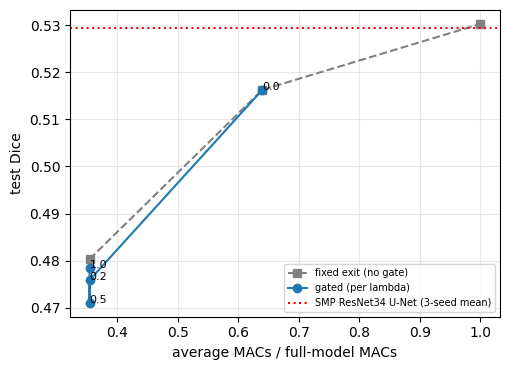

In [ ]:
# ===== Cell C: lambda sweep + table + FLOPs-vs-Dice plot =====
LAMS = [0.5] if SMOKE else [0.0, 0.2, 0.5, 1.0]
dyn = {}
for lam in LAMS:
    t0 = time.time(); m, r = train_stage2(lam, 42, E2); dyn[lam] = r
    print(f"lam {lam}: TEST Dice {r['dice']:.4f} IoU {r['iou']:.4f} prec {r['prec']:.4f} rec {r['rec']:.4f} | exits {[round(f, 2) for f in r['frac']]} | MACs ratio {r['macs_ratio']:.3f} | {(time.time()-t0)/60:.1f} min")
    json.dump({str(k): v for k, v in dyn.items()}, open(WORK / "dyn_results_s42.json", "w"), indent=1)

rows = [{"lambda": k, "Dice": v["dice"], "IoU": v["iou"], "Prec": v["prec"], "Rec": v["rec"], "MACs ratio": v["macs_ratio"],
         "exit1/2/3": [round(f, 2) for f in v["frac"]], "fixed-exit Dice": [round(d, 3) for d in v["fixed"]]} for k, v in dyn.items()]
print(pd.DataFrame(rows).round(4).to_string(index=False))

ref = dyn[min(dyn)]                              # the smallest lambda's per-exit (fixed) points = "no gate" baselines
Fr = [f / m.F[2] for f in m.F]                 # exit costs (incl. gate overhead) relative to the full path
plt.figure(figsize=(5.2, 3.8))
plt.plot(Fr, ref["fixed"], "s--", color="gray", label="fixed exit (no gate)")
plt.plot([v["macs_ratio"] for v in dyn.values()], [v["dice"] for v in dyn.values()], "o-", label="gated (per lambda)")
for k, v in dyn.items(): plt.annotate(f"{k}", (v["macs_ratio"], v["dice"]), fontsize=8)
plt.axhline(0.5293, color="r", ls=":", label="SMP ResNet34 U-Net (3-seed mean)")
plt.xlabel("average MACs / full-model MACs"); plt.ylabel("test Dice"); plt.legend(fontsize=7); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

cost ratio per exit: [0.355, 0.64, 1.0]
stage-1 model, fixed exit mean Dice  val: [0.47, 0.504, 0.514]  test: [0.452, 0.527, 0.538]

(a) oracle headroom on test (uses labels, so it is only an upper bound)
  delta 0.00: Dice 0.562 at MACs ratio 0.733 | exits used [0.24, 0.32, 0.44]
  delta 0.02: Dice 0.560 at MACs ratio 0.611 | exits used [0.42, 0.33, 0.25]
  delta 0.05: Dice 0.554 at MACs ratio 0.545 | exits used [0.54, 0.29, 0.17]
  delta 0.10: Dice 0.541 at MACs ratio 0.474 | exits used [0.65, 0.29, 0.06]

(b) Spearman correlation (val + test pooled, n = 144)
  max prob at exit 1: vs exit-1 Dice +0.55 | vs gain of exit 3 over exit 1 -0.15
  mean entropy at exit 1: vs exit-1 Dice -0.16 | vs gain of exit 3 over exit 1 +0.08

(c) confidence-threshold policy
 tau  val Dice  val MACs  test Dice  test MACs         test exits
0.50     0.488     0.385      0.467      0.383 [0.92, 0.07, 0.01]
0.60     0.488     0.385      0.467      0.383 [0.92, 0.07, 0.01]
0.70     0.489     0.394      0.481

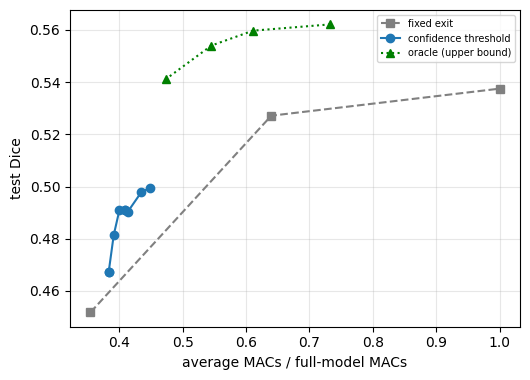

In [ ]:
# ===== Cell D: why did the gates collapse? headroom + signal diagnostics (no training, takes seconds) =====
from scipy.stats import spearmanr
m1 = new_model(42); m1.load_state_dict(torch.load(WORK / "dyn_stage1_s42.pt", map_location=DEVICE)); m1.eval()

@torch.no_grad()
def exit_outputs(model, dl):
    Ls, Ys = [[], [], []], []
    for x, y in dl:
        o = model.forward_all(x.to(DEVICE))
        for k in range(3): Ls[k].append(o["logits"][k].cpu())
        Ys.append(y)
    return [torch.cat(l) for l in Ls], torch.cat(Ys)

def per_image(L, Y):
    D = torch.stack([batch_metrics(l, Y, 0.5)[0] for l in L], 1)                                   # N x 3: Dice per image and exit
    P = [torch.sigmoid(l) for l in L]
    conf = torch.stack([p.amax(dim=(1, 2, 3)) for p in P], 1)                                       # N x 3: max probability
    ent = torch.stack([(-(p * torch.log(p + 1e-6) + (1 - p) * torch.log(1 - p + 1e-6))).mean((1, 2, 3)) for p in P], 1)
    return D, conf, ent

Lv, Yv = exit_outputs(m1, make_dl(va_idx, eval_tf, False)); Lt, Yt = exit_outputs(m1, make_dl(te_idx, eval_tf, False))
Dv, cv, ev = per_image(Lv, Yv); Dt, ct, et = per_image(Lt, Yt)
Fr3 = torch.tensor([f / m1.F[2] for f in m1.F])
print("cost ratio per exit:", [round(f, 3) for f in Fr3.tolist()])
print("stage-1 model, fixed exit mean Dice  val:", [round(v, 3) for v in Dv.mean(0).tolist()], " test:", [round(v, 3) for v in Dt.mean(0).tolist()])

# (a) headroom: an ORACLE that knows the labels picks the cheapest exit within delta of the best exit (upper bound, not achievable)
print("\n(a) oracle headroom on test (uses labels, so it is only an upper bound)")
oracle = {}
for delta in [0.0, 0.02, 0.05, 0.10]:
    k = (Dt >= (Dt.max(1, keepdim=True).values - delta)).float().argmax(1)
    oracle[delta] = (Fr3[k].mean().item(), Dt[torch.arange(len(k)), k].mean().item())
    print(f"  delta {delta:.2f}: Dice {oracle[delta][1]:.3f} at MACs ratio {oracle[delta][0]:.3f} | exits used {[round((k == j).float().mean().item(), 2) for j in range(3)]}")

# (b) signal: does the exit-1 head's own uncertainty say anything about difficulty?
print("\n(b) Spearman correlation (val + test pooled, n = %d)" % (len(Dv) + len(Dt)))
D, c, e = torch.cat([Dv, Dt]), torch.cat([cv, ct]), torch.cat([ev, et]); gain = D[:, 2] - D[:, 0]
for name, f in [("max prob at exit 1", c[:, 0]), ("mean entropy at exit 1", e[:, 0])]:
    print(f"  {name}: vs exit-1 Dice {spearmanr(f.numpy(), D[:, 0].numpy())[0]:+.2f} | vs gain of exit 3 over exit 1 {spearmanr(f.numpy(), gain.numpy())[0]:+.2f}")

# (c) confidence-threshold exit policy (no training): leave at the first head whose max probability >= tau
def policy(conf, Dm, tau):
    k = torch.full((len(Dm),), 2); k[conf[:, 1] >= tau] = 1; k[conf[:, 0] >= tau] = 0
    return Dm[torch.arange(len(Dm)), k].mean().item(), Fr3[k].mean().item(), [round((k == j).float().mean().item(), 2) for j in range(3)]
print("\n(c) confidence-threshold policy")
rows, taus = [], [0.5, 0.6, 0.7, 0.8, 0.85, 0.9, 0.95, 0.98, 0.99]
for tau in taus:
    (dv, mv, _), (dt, mt, fr) = policy(cv, Dv, tau), policy(ct, Dt, tau)
    rows.append({"tau": tau, "val Dice": dv, "val MACs": mv, "test Dice": dt, "test MACs": mt, "test exits": fr})
print(pd.DataFrame(rows).round(3).to_string(index=False))
target = Dv[:, 2].mean().item() - 0.01                    # rule fixed on VAL: cheapest tau within 0.01 Dice of the full model
ok = [r for r in rows if r["val Dice"] >= target]
if ok:
    best = min(ok, key=lambda r: r["val MACs"])
    print(f"\nchosen on val (within 0.01 Dice of exit 3): tau {best['tau']} -> TEST Dice {best['test Dice']:.4f} at MACs ratio {best['test MACs']:.3f}, exits {best['test exits']}")
else:
    print("\nno tau keeps val Dice within 0.01 of exit 3")

plt.figure(figsize=(5.4, 3.9))
plt.plot(Fr3.tolist(), Dt.mean(0).tolist(), "s--", color="gray", label="fixed exit")
plt.plot([r["test MACs"] for r in rows], [r["test Dice"] for r in rows], "o-", label="confidence threshold")
plt.plot([v[0] for v in oracle.values()], [v[1] for v in oracle.values()], "^:", color="green", label="oracle (upper bound)")
plt.xlabel("average MACs / full-model MACs"); plt.ylabel("test Dice"); plt.legend(fontsize=7); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

In [ ]:
# ===== Add-on Cell 1: extract frozen-exit features and per-image oracle targets =====
import copy, time, json, math
from pathlib import Path
from torch.utils.data import TensorDataset, DataLoader

STAGE1_CK = WORK / "dyn_stage1_s42.pt"
assert STAGE1_CK.exists(), f"Missing {STAGE1_CK}. Run the existing Stage-1 training cell first."

# Load the best Stage-1 segmentation model. Its segmentation weights remain frozen.
router_model = EarlyExitUNet(use_unc=True).to(DEVICE)
router_model.load_state_dict(torch.load(STAGE1_CK, map_location=DEVICE))
router_model.F = [measure_macs(router_model, k) for k in (1, 2, 3)]
COSTS = torch.tensor(router_model.F, dtype=torch.float32) / float(router_model.F[2])
print("Exit MACs (G):", [round(v / 1e9, 3) for v in router_model.F])
print("Normalized costs:", [round(v.item(), 4) for v in COSTS])

@torch.no_grad()
def make_gate_input_v2(gate, feature_map, logits, use_unc=True, top_fraction=0.10):
    """Pooled semantic feature + localised uncertainty statistics."""
    pooled = feature_map.mean((2, 3))
    if not use_unc:
        unc = torch.zeros((len(logits), 2), device=logits.device)
    else:
        p = torch.sigmoid(logits).flatten(1).clamp(1e-6, 1 - 1e-6)
        ent = -(p * torch.log(p) + (1-p) * torch.log(1-p)) / math.log(2.0)  # [0,1]
        k = max(1, int(ent.shape[1] * top_fraction))
        top_ent = ent.topk(k, dim=1).values.mean(1)
        high_ent_fraction = (ent > 0.80).float().mean(1)
        unc = torch.stack([top_ent, high_ent_fraction], dim=1)
    return torch.cat([pooled, unc], dim=1)

@torch.no_grad()
def per_image_dice_from_logits(logits, masks, thr=0.5, eps=1e-7):
    pred = (torch.sigmoid(logits) > thr).float()
    dims = (1, 2, 3)
    tp = (pred * masks).sum(dims)
    fp = (pred * (1-masks)).sum(dims)
    fn = ((1-pred) * masks).sum(dims)
    return (2*tp + eps) / (2*tp + fp + fn + eps)

@torch.no_grad()
def collect_router_data(model, loader, use_unc=True):
    """Collect gate inputs and per-image Dice for all three fixed exits."""
    model.eval()
    g1_all, g2_all, dice_all = [], [], []
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        f1 = model.s1(xb)
        f2 = model.s2(f1)
        f3 = model.s3(f2)
        l1 = model.head1([f3, f2, f1])
        q1 = make_gate_input_v2(model.gate1, f3, l1, use_unc=use_unc)
        f4 = model.s4(f3)
        l2 = model.head2([f4, f3, f2, f1])
        q2 = make_gate_input_v2(model.gate2, f4, l2, use_unc=use_unc)
        l3 = model._dec(f1, f2, f3, f4, model.s5(f4))
        ds = torch.stack([
            per_image_dice_from_logits(l1, yb),
            per_image_dice_from_logits(l2, yb),
            per_image_dice_from_logits(l3, yb)
        ], dim=1)
        g1_all.append(q1.cpu()); g2_all.append(q2.cpu()); dice_all.append(ds.cpu())
    return torch.cat(g1_all), torch.cat(g2_all), torch.cat(dice_all)

# Use deterministic, non-augmented images for router supervision and validation.
router_train_dl = make_dl(tr_idx, eval_tf, False)
router_val_dl = make_dl(va_idx, eval_tf, False)
t0 = time.time()
train_g1, train_g2, train_exit_dice = collect_router_data(router_model, router_train_dl, use_unc=True)
val_g1, val_g2, val_exit_dice = collect_router_data(router_model, router_val_dl, use_unc=True)
print("Feature shapes:", train_g1.shape, train_g2.shape, train_exit_dice.shape)
print(f"Feature extraction time: {(time.time()-t0)/60:.1f} min")

# Diagnostic: does the localised uncertainty signal track the benefit of deeper computation?
from scipy.stats import spearmanr
u = train_g1[:, -2].numpy()
improvement = (train_exit_dice[:, 2] - train_exit_dice[:, 0]).numpy()
rho, pval = spearmanr(u, improvement)
print(f"Train Spearman(top-decile entropy, Exit3-Exit1 Dice): rho={rho:.3f}, p={pval:.4g}")
print("Train top-decile entropy quantiles:", np.quantile(u, [0, .25, .5, .75, 1]).round(4))


Exit MACs (G): [2.323, 4.192, 6.55]
Normalized costs: [0.3546, 0.6399, 1.0]
Feature shapes: torch.Size([575, 130]) torch.Size([575, 258]) torch.Size([575, 3])
Feature extraction time: 0.0 min
Train Spearman(top-decile entropy, Exit3-Exit1 Dice): rho=0.144, p=0.0005326
Train top-decile entropy quantiles: [0.0003 0.0168 0.0275 0.0478 0.1511]


unc=1 alpha=0.00 | val Dice=0.4759 | exits=[0.819, 0.014, 0.167] | expected MAC ratio=0.466 | train oracle exits=[0.17043478786945343, 0.30086955428123474, 0.5286956429481506]
unc=1 alpha=0.05 | val Dice=0.4784 | exits=[0.681, 0.069, 0.25] | expected MAC ratio=0.536 | train oracle exits=[0.3026086986064911, 0.36347827315330505, 0.33391305804252625]
unc=1 alpha=0.10 | val Dice=0.4744 | exits=[0.569, 0.264, 0.167] | expected MAC ratio=0.537 | train oracle exits=[0.40173912048339844, 0.40869563817977905, 0.18956521153450012]
unc=1 alpha=0.15 | val Dice=0.4862 | exits=[0.597, 0.194, 0.208] | expected MAC ratio=0.545 | train oracle exits=[0.5182608962059021, 0.3843478262424469, 0.09739130735397339]
unc=1 alpha=0.20 | val Dice=0.4743 | exits=[0.694, 0.25, 0.056] | expected MAC ratio=0.462 | train oracle exits=[0.6034782528877258, 0.3513043522834778, 0.04521739110350609]
unc=0 alpha=0.00 | val Dice=0.5037 | exits=[0.042, 0.639, 0.319] | expected MAC ratio=0.743 | train oracle exits=[0.1704347

,alpha,uncertainty,val_dice,macs_ratio,exit1,exit2,exit3
5,0.00,False,0.5037,0.7431,0.0417,0.6389,0.3194
6,0.05,False,0.4784,0.5358,0.6806,0.0694,0.2500
7,0.10,False,0.4739,0.4789,0.7222,0.1528,0.1250
8,0.15,False,0.4865,0.5435,0.5833,0.2222,0.1944
9,0.20,False,0.4833,0.4985,0.5833,0.3472,0.0694
0,0.00,True,0.4759,0.4661,0.8194,0.0139,0.1667
1,0.05,True,0.4784,0.5358,0.6806,0.0694,0.2500
2,0.10,True,0.4744,0.5375,0.5694,0.2639,0.1667
3,0.15,True,0.4862,0.5446,0.5972,0.1944,0.2083
4,0.20,True,0.4743,0.4618,0.6944,0.2500,0.0556


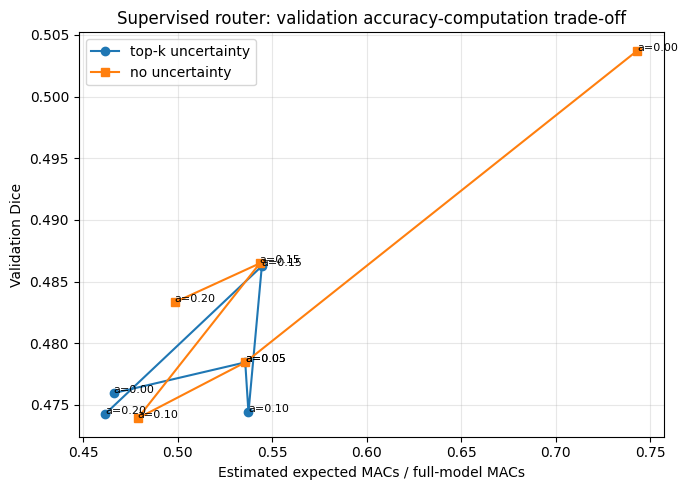

In [ ]:
# ===== Add-on Cell 2: train gates with oracle routing targets; uncertainty ablation =====
# For each training image, choose the exit maximizing: per-image Dice - alpha * normalized MACs.
# Only the small gate MLPs are trained here; the encoder and segmentation exits are frozen.

ROUTER_ALPHAS = [0.00, 0.05, 0.10, 0.15, 0.20]
ROUTER_EPOCHS = 40
ROUTER_BATCH = 64
ROUTER_LR = 1e-3

# Preserve the Stage-1 gate initialisation so every alpha/ablation starts identically.
base_gate1_state = copy.deepcopy(router_model.gate1.net.state_dict())
base_gate2_state = copy.deepcopy(router_model.gate2.net.state_dict())

@torch.no_grad()
def route_from_gate_logits(q1, q2, gate1, gate2, device=DEVICE):
    z1 = gate1(q1.to(device)).argmax(1).cpu()  # 0=exit1, 1=continue
    z2 = gate2(q2.to(device)).argmax(1).cpu()  # 0=exit2, 1=exit3
    exits = torch.full((len(z1),), 2, dtype=torch.long)
    exits[z1 == 0] = 0
    continue_ids = torch.where(z1 == 1)[0]
    if len(continue_ids):
        exits[continue_ids[z2[continue_ids] == 0]] = 1
    return exits

def balanced_weights(target):
    counts = torch.bincount(target, minlength=2).float()
    present = counts > 0
    w = torch.zeros(2)
    w[present] = len(target) / (present.sum() * counts[present])
    return w

def fit_binary_gate(net, features, targets, epochs=ROUTER_EPOCHS):
    features = features.float()
    targets = targets.long()
    ds = TensorDataset(features, targets)
    dl = DataLoader(ds, batch_size=ROUTER_BATCH, shuffle=True)
    net.train()
    opt = torch.optim.AdamW(net.parameters(), lr=ROUTER_LR, weight_decay=1e-4)
    weights = balanced_weights(targets).to(DEVICE)
    loss_fn = nn.CrossEntropyLoss(weight=weights)
    for _ in range(epochs):
        for q, t in dl:
            q, t = q.to(DEVICE), t.to(DEVICE)
            loss = loss_fn(net(q), t)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
    net.eval()

@torch.no_grad()
def evaluate_router(q1, q2, dice_matrix, gate1, gate2):
    exits = route_from_gate_logits(q1, q2, gate1, gate2)
    rows = torch.arange(len(exits))
    selected_dice = dice_matrix[rows, exits]
    fractions = [(exits == k).float().mean().item() for k in range(3)]
    mac_ratio = sum(f * COSTS[k].item() for k, f in enumerate(fractions))
    return {
        "dice": selected_dice.mean().item(),
        "frac": fractions,
        "macs_ratio": mac_ratio,
        "exit_ids": exits,
        "per_image_dice": selected_dice
    }

router_results = {}
for use_unc in [True, False]:
    # Use the same semantic features; zero the two uncertainty channels for the ablation.
    tr1, tr2 = train_g1.clone(), train_g2.clone()
    va1, va2 = val_g1.clone(), val_g2.clone()
    if not use_unc:
        tr1[:, -2:] = 0; tr2[:, -2:] = 0
        va1[:, -2:] = 0; va2[:, -2:] = 0

    for alpha in ROUTER_ALPHAS:
        # Reset gate weights for a fair comparison across alpha values.
        router_model.gate1.net.load_state_dict(base_gate1_state)
        router_model.gate2.net.load_state_dict(base_gate2_state)
        router_model.gate1.use_unc = use_unc
        router_model.gate2.use_unc = use_unc

        # Oracle exit labels are derived ONLY from training-set ground-truth masks.
        utility = train_exit_dice - float(alpha) * COSTS.view(1, 3)
        oracle_exit = utility.argmax(1)
        target_gate1 = (oracle_exit != 0).long()  # 0=exit1, 1=continue
        keep_for_gate2 = oracle_exit != 0
        target_gate2 = (oracle_exit[keep_for_gate2] == 2).long()  # 0=exit2, 1=exit3

        fit_binary_gate(router_model.gate1.net, tr1, target_gate1)
        if keep_for_gate2.any():
            fit_binary_gate(router_model.gate2.net, tr2[keep_for_gate2], target_gate2)

        val_result = evaluate_router(va1, va2, val_exit_dice,
                                     router_model.gate1.net, router_model.gate2.net)
        key = (float(alpha), bool(use_unc))
        ck = WORK / f"router_alpha{alpha:.2f}_unc{int(use_unc)}_s42.pt"
        torch.save(router_model.state_dict(), ck)
        router_results[key] = {
            "val_dice": val_result["dice"],
            "frac": val_result["frac"],
            "macs_ratio": val_result["macs_ratio"],
            "checkpoint": str(ck),
            "target_train_exit_fractions": [(oracle_exit == k).float().mean().item() for k in range(3)],
            "gate1_target_continue_fraction": target_gate1.float().mean().item(),
            "gate2_train_count": int(keep_for_gate2.sum())
        }
        print(f"unc={int(use_unc)} alpha={alpha:.2f} | val Dice={val_result['dice']:.4f} "
              f"| exits={[round(v,3) for v in val_result['frac']]} "
              f"| expected MAC ratio={val_result['macs_ratio']:.3f} "
              f"| train oracle exits={router_results[key]['target_train_exit_fractions']}")

router_table = pd.DataFrame([
    {"alpha": a, "uncertainty": u, "val_dice": r["val_dice"],
     "macs_ratio": r["macs_ratio"], "exit1": r["frac"][0],
     "exit2": r["frac"][1], "exit3": r["frac"][2]}
    for (a, u), r in router_results.items()
])
print("\nValidation-only router comparison:")
display(router_table.sort_values(["uncertainty", "alpha"]).round(4))

plt.figure(figsize=(7, 5))
for u, label, marker in [(True, "top-k uncertainty", "o"), (False, "no uncertainty", "s")]:
    sub = router_table[router_table.uncertainty == u]
    plt.plot(sub.macs_ratio, sub.val_dice, marker=marker, label=label)
    for _, row in sub.iterrows():
        plt.annotate(f"a={row.alpha:.2f}", (row.macs_ratio, row.val_dice), fontsize=8)
plt.xlabel("Estimated expected MACs / full-model MACs")
plt.ylabel("Validation Dice")
plt.title("Supervised router: validation accuracy-computation trade-off")
plt.grid(alpha=.3); plt.legend(); plt.tight_layout(); plt.show()

with open(WORK / "router_validation_results_s42.json", "w") as f:
    json.dump({f"alpha={a:.2f}_unc={int(u)}": {k:v for k,v in r.items() if k != "checkpoint"}
               | {"checkpoint":r["checkpoint"]} for (a,u),r in router_results.items()}, f, indent=2)


VALIDATION | {'dice': 0.4744, 'iou': 0.356, 'precision': 0.5388, 'recall': 0.5406, 'frac': [0.5694444179534912, 0.2638888955116272, 0.1666666716337204], 'expected_macs_ratio': 0.5375}
Validation inference latency: conditional=5.03 ms/image | all-exits=5.35 ms/image
Latency speedup (all-exits / conditional): 1.064 x

FINAL HELD-OUT TEST:
{
  "dice": 0.47372591495513916,
  "iou": 0.36598047614097595,
  "precision": 0.5889384746551514,
  "recall": 0.505148708820343,
  "frac": [
    0.6111111044883728,
    0.1527777761220932,
    0.2361111044883728
  ],
  "expected_macs_ratio": 0.5505936012360273,
  "selected_alpha": 0.1,
  "selected_use_uncertainty": true,
  "validation_conditional_ms_per_image": 5.029907847225938,
  "validation_all_exits_ms_per_image": 5.3496816527614195
}


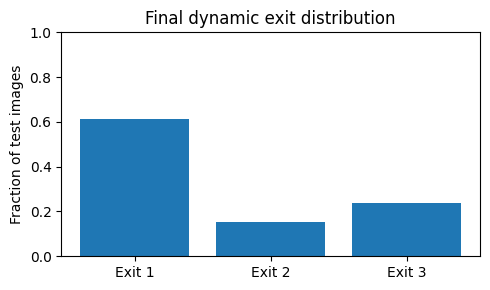

In [ ]:
# ===== Add-on Cell 3: true conditional inference, validation timing, and ONE final test =====
# Choose alpha and uncertainty setting from the validation table/plot above.
SELECTED_ALPHA = 0.10       # change after reviewing validation results
SELECTED_USE_UNC = True     # compare True vs False using validation only

selected_key = (float(SELECTED_ALPHA), bool(SELECTED_USE_UNC))
assert selected_key in router_results, f"Choose alpha from {ROUTER_ALPHAS} and a valid uncertainty setting."
selected_ck = Path(router_results[selected_key]["checkpoint"])
router_model.load_state_dict(torch.load(selected_ck, map_location=DEVICE))
router_model.gate1.use_unc = SELECTED_USE_UNC
router_model.gate2.use_unc = SELECTED_USE_UNC
router_model.eval()

@torch.no_grad()
def dynamic_infer(model, xb, use_unc=True):
    """Conditional batch inference: later stages process only samples that continue."""
    model.eval()
    B, _, H, W = xb.shape
    output = torch.empty((B, 1, H, W), device=xb.device)
    exits = torch.full((B,), 2, dtype=torch.long, device=xb.device)

    f1 = model.s1(xb); f2 = model.s2(f1); f3 = model.s3(f2)
    l1 = model.head1([f3, f2, f1])
    q1 = make_gate_input_v2(model.gate1, f3, l1, use_unc=use_unc)
    go1 = model.gate1.net(q1).argmax(1)
    stop1 = go1 == 0
    if stop1.any():
        output[stop1] = l1[stop1]
        exits[stop1] = 0

    keep1 = torch.where(~stop1)[0]
    if len(keep1) == 0:
        return output, exits

    f1r, f2r, f3r = f1[keep1], f2[keep1], f3[keep1]
    f4 = model.s4(f3r)
    l2 = model.head2([f4, f3r, f2r, f1r])
    q2 = make_gate_input_v2(model.gate2, f4, l2, use_unc=use_unc)
    go2 = model.gate2.net(q2).argmax(1)
    stop2 = go2 == 0
    if stop2.any():
        ids2 = keep1[stop2]
        output[ids2] = l2[stop2]
        exits[ids2] = 1

    keep2_local = torch.where(~stop2)[0]
    if len(keep2_local):
        ids3 = keep1[keep2_local]
        f5 = model.s5(f4[keep2_local])
        l3 = model._dec(f1r[keep2_local], f2r[keep2_local],
                        f3r[keep2_local], f4[keep2_local], f5)
        output[ids3] = l3
        exits[ids3] = 2
    return output, exits

@torch.no_grad()
def evaluate_dynamic_loader(model, loader, use_unc=True):
    model.eval()
    logits_all, masks_all, exits_all = [], [], []
    for xb, yb in loader:
        xb = xb.to(DEVICE)
        lg, ex = dynamic_infer(model, xb, use_unc=use_unc)
        logits_all.append(lg.cpu()); masks_all.append(yb.cpu()); exits_all.append(ex.cpu())
    logits = torch.cat(logits_all); masks = torch.cat(masks_all); exits = torch.cat(exits_all)
    metrics = [v.mean().item() for v in batch_metrics(logits, masks, 0.5)]
    frac = [(exits == k).float().mean().item() for k in range(3)]
    mac_ratio = sum(frac[k] * COSTS[k].item() for k in range(3))
    return {"dice":metrics[0], "iou":metrics[1], "precision":metrics[2], "recall":metrics[3],
            "frac":frac, "expected_macs_ratio":mac_ratio, "logits":logits, "masks":masks}

# Validate routing and measure actual conditional latency versus all-exits computation.
val_dynamic = evaluate_dynamic_loader(router_model, router_val_dl, SELECTED_USE_UNC)
print("VALIDATION |", {k: round(v,4) if isinstance(v,float) else v for k,v in val_dynamic.items() if k not in ["logits","masks"]})

@torch.no_grad()
def time_loader_forward(fn, loader, repeats=3):
    # Warm-up
    for j, (xb, _) in enumerate(loader):
        fn(xb.to(DEVICE))
        if j == 1: break
    if torch.cuda.is_available(): torch.cuda.synchronize()
    times=[]; n_images=0
    for _ in range(repeats):
        t0=time.perf_counter(); n_images=0
        for xb, _ in loader:
            fn(xb.to(DEVICE)); n_images += len(xb)
        if torch.cuda.is_available(): torch.cuda.synchronize()
        times.append((time.perf_counter()-t0)/n_images*1000)
    return float(np.median(times))

ms_dynamic = time_loader_forward(lambda xb: dynamic_infer(router_model, xb, SELECTED_USE_UNC), router_val_dl)
ms_all = time_loader_forward(lambda xb: router_model.forward_all(xb), router_val_dl)
print(f"Validation inference latency: conditional={ms_dynamic:.2f} ms/image | all-exits={ms_all:.2f} ms/image")
print("Latency speedup (all-exits / conditional):", round(ms_all/max(ms_dynamic,1e-9), 3), "x")

# IMPORTANT: test set is evaluated once, only after alpha/uncertainty selection on validation.
final_dynamic_test = evaluate_dynamic_loader(router_model, test_dl, SELECTED_USE_UNC)
final_summary = {k:v for k,v in final_dynamic_test.items() if k not in ["logits","masks"]}
final_summary.update({"selected_alpha":SELECTED_ALPHA, "selected_use_uncertainty":SELECTED_USE_UNC,
                      "validation_conditional_ms_per_image":ms_dynamic,
                      "validation_all_exits_ms_per_image":ms_all})
print("\nFINAL HELD-OUT TEST:")
print(json.dumps(final_summary, indent=2))
with open(WORK / "final_dynamic_router_test_s42.json", "w") as f:
    json.dump(final_summary, f, indent=2)

# Exit distribution plot for the held-out test set.
plt.figure(figsize=(5,3))
plt.bar(["Exit 1", "Exit 2", "Exit 3"], final_summary["frac"])
plt.ylabel("Fraction of test images"); plt.title("Final dynamic exit distribution")
plt.ylim(0,1); plt.tight_layout(); plt.show()


In [ ]:
# ===== Cell E: held-out cue search + paired bootstrap (uses variables from Cell D; no training, seconds) =====
def soft_stats(L):                                    # L = logits of one exit, N x 1 x H x W
    p = torch.sigmoid(L).flatten(1); k = max(1, int(0.01 * p.shape[1]))
    return {"predicted area": (p > 0.5).float().mean(1), "soft area": p.mean(1), "top-1% mean prob": p.topk(k, dim=1).values.mean(1)}

def dice_between(a, b, eps=1e-7):                      # per-image Dice between two binary predictions
    a, b = (torch.sigmoid(a) > 0.5).float().flatten(1), (torch.sigmoid(b) > 0.5).float().flatten(1)
    return (2 * (a * b).sum(1) + eps) / (a.sum(1) + b.sum(1) + eps)

def cues(L):
    s1, s2 = soft_stats(L[0]), soft_stats(L[1])
    out = {"gate1 | exit-1 " + k: v for k, v in s1.items()}
    out.update({"gate2 | exit-2 " + k: v for k, v in s2.items()})
    out["gate2 | agreement exit1 vs exit2"] = dice_between(L[0], L[1])
    return out

cv_, ct_ = cues(Lv), cues(Lt)
print("Spearman rho between a cue and the Dice gain of going deeper (gate1: exit3 - exit1, gate2: exit3 - exit2)")
for name in cv_:
    g = (lambda D: D[:, 2] - D[:, 0]) if name.startswith("gate1") else (lambda D: D[:, 2] - D[:, 1])
    rv = spearmanr(cv_[name].numpy(), g(Dv).numpy())[0]; rt = spearmanr(ct_[name].numpy(), g(Dt).numpy())[0]
    print(f"  {name:36s} val {rv:+.2f} | test {rt:+.2f}")
print("A usable cue needs the SAME sign on val and test and |rho| of at least about 0.3.")

rng = np.random.RandomState(0)
def paired_ci(a, b, n=2000):
    d = (a - b).numpy(); m = d[rng.randint(0, len(d), (n, len(d)))].mean(1)
    return d.mean(), np.percentile(m, 2.5), np.percentile(m, 97.5)
print("\nPaired bootstrap on the test split: mean per-image Dice difference and 95% CI")
for a, b, nm in [(2, 1, "exit 3 - exit 2"), (1, 0, "exit 2 - exit 1"), (2, 0, "exit 3 - exit 1")]:
    m, lo, hi = paired_ci(Dt[:, a], Dt[:, b]); print(f"  {nm}: {m:+.3f}  [{lo:+.3f}, {hi:+.3f}]")
sd = Dt[:, 2].std().item(); print(f"  per-image Dice std (exit 3, test) {sd:.3f} -> standard error of a 72-image mean Dice about {sd / len(Dt) ** 0.5:.3f}")

Spearman rho between a cue and the Dice gain of going deeper (gate1: exit3 - exit1, gate2: exit3 - exit2)
  gate1 | exit-1 predicted area        val -0.12 | test +0.01
  gate1 | exit-1 soft area             val -0.10 | test +0.01
  gate1 | exit-1 top-1% mean prob      val -0.11 | test +0.02
  gate2 | exit-2 predicted area        val -0.10 | test +0.09
  gate2 | exit-2 soft area             val -0.10 | test +0.10
  gate2 | exit-2 top-1% mean prob      val -0.10 | test +0.09
  gate2 | agreement exit1 vs exit2     val +0.18 | test -0.13
A usable cue needs the SAME sign on val and test and |rho| of at least about 0.3.

Paired bootstrap on the test split: mean per-image Dice difference and 95% CI
  exit 3 - exit 2: +0.010  [-0.004, +0.026]
  exit 2 - exit 1: +0.075  [+0.040, +0.119]
  exit 3 - exit 1: +0.086  [+0.047, +0.125]
  per-image Dice std (exit 3, test) 0.300 -> standard error of a 72-image mean Dice about 0.035


In [ ]:
# ===== Cell F: fair latency + MACs for static vs multi-exit vs dynamic router (no training, about 1 minute) =====
def count_macs(module, fn, x):
    cnt, hs = [0], []
    def hook(m, i, o):
        if isinstance(m, nn.Conv2d): cnt[0] += (o.numel() // o.shape[0]) * (m.in_channels // m.groups) * m.kernel_size[0] * m.kernel_size[1]
        else: cnt[0] += m.in_features * m.out_features
    for mod in module.modules():
        if isinstance(mod, (nn.Conv2d, nn.Linear)): hs.append(mod.register_forward_hook(hook))
    with torch.no_grad(): fn(x)
    for h in hs: h.remove()
    return cnt[0]

@torch.no_grad()
def time_ms(fn, x, warm=10, reps=50):
    for _ in range(warm): fn(x)
    if torch.cuda.is_available(): torch.cuda.synchronize()
    ts = []
    for _ in range(reps):
        t0 = time.perf_counter(); fn(x)
        if torch.cuda.is_available(): torch.cuda.synchronize()
        ts.append((time.perf_counter() - t0) * 1000)
    return float(np.median(ts))

smp_model = smp.Unet("resnet34", encoder_weights=None, in_channels=3, classes=1).to(DEVICE).eval()   # weights do not change latency
router_model.eval(); xs = torch.cat([xb for xb, _ in router_val_dl]).to(DEVICE); x1, x16 = xs[:1], xs[:16]
static = {"SMP ResNet34 U-Net (static)": (smp_model, lambda x: smp_model(x)),
          "multi-exit, exit 1 only": (router_model, lambda x: router_model.forward_upto(x, 1)),
          "multi-exit, exit 2 only": (router_model, lambda x: router_model.forward_upto(x, 2)),
          "multi-exit, exit 3 (full path)": (router_model, lambda x: router_model.forward_upto(x, 3))}
rows = []
for name, (mod, fn) in static.items():
    rows.append({"model": name, "GMACs": count_macs(mod, fn, x1) / 1e9, "ms/img (batch 1)": time_ms(fn, x1), "ms/img (batch 16)": time_ms(fn, x16) / 16})

per_img = []                                      # dynamic router: per-image latency on the real validation images
for i in range(len(xs)):
    xi = xs[i:i + 1]
    if i < 3: dynamic_infer(router_model, xi, SELECTED_USE_UNC)          # warm-up
    if torch.cuda.is_available(): torch.cuda.synchronize()
    t0 = time.perf_counter(); dynamic_infer(router_model, xi, SELECTED_USE_UNC)
    if torch.cuda.is_available(): torch.cuda.synchronize()
    per_img.append((time.perf_counter() - t0) * 1000)
rows.append({"model": "dynamic router (val images, batch 1)", "GMACs": val_dynamic["expected_macs_ratio"] * router_model.F[2] / 1e9,
             "ms/img (batch 1)": float(np.mean(per_img)), "ms/img (batch 16)": float("nan")})
print(pd.DataFrame(rows).round(2).to_string(lindex=False))

                               model  GMACs  ms/img (batch 1)  ms/img (batch 16)
         SMP ResNet34 U-Net (static)   7.81              6.63               3.60
             multi-exit, exit 1 only   2.32              2.63               1.35
             multi-exit, exit 2 only   4.19              4.99               2.11
      multi-exit, exit 3 (full path)   6.55              7.72               3.27
dynamic router (val images, batch 1)   3.52              5.52                NaN


In [ ]:
# ===== Cell G: final multi-exit model (deep supervision, no gates), 3 seeds, 80 epochs cosine, about 35 min =====
def eval_exits(model, dl):
    model.eval(); Ls, Ys = [[], [], []], []
    with torch.no_grad():
        for x, y in dl:
            o = model.forward_all(x.to(DEVICE))
            for k in range(3): Ls[k].append(o["logits"][k].cpu())
            Ys.append(y)
    Y = torch.cat(Ys)
    return [[v.mean().item() for v in batch_metrics(torch.cat(Ls[k]), Y, 0.5)] for k in range(3)]    # per exit: [dice, iou, prec, rec]

def train_multiexit(seed, epochs=80, lr=1e-4):
    set_seed(seed); gen.manual_seed(seed)
    tr, va, te = make_dl(tr_idx, train_tf, True), make_dl(va_idx, eval_tf, False), make_dl(te_idx, eval_tf, False)
    m = new_model(seed); opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=1e-4)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs); best, ck = -1.0, WORK / f"multiexit_s{seed}.pt"
    for ep in range(epochs):
        m.train()
        for x, y in tr:
            x, y = x.to(DEVICE), y.to(DEVICE)
            loss = sum(w * seg_loss(l, y) for w, l in zip(W, m.forward_all(x)["logits"]))
            opt.zero_grad(); loss.backward(); opt.step()
        sch.step(); v = float(np.mean([e[0] for e in eval_exits(m, va)]))        # mean val Dice over the three exits
        if v > best: best = v; torch.save(m.state_dict(), ck)
    m.load_state_dict(torch.load(ck, map_location=DEVICE)); return eval_exits(m, te), best

F_exit = new_model(42).F
me = {}
for seed in [42, 43, 44]:
    t0 = time.time(); me[seed], bv = train_multiexit(seed)
    print(seed, "best mean val Dice", round(bv, 4), "| test per exit [dice, iou, prec, rec]:", [[round(v, 3) for v in e] for e in me[seed]], f"| {(time.time()-t0)/60:.1f} min")
    json.dump({str(k): v for k, v in me.items()}, open(WORK / "multiexit_3seeds.json", "w"))
A = np.array([me[s] for s in me])                      # seeds x exits x metrics
for k in range(3):
    print(f"exit {k+1} ({F_exit[k]/1e9:.2f} GMACs, {F_exit[k]/F_exit[2]:.2f} of full):",
          {n: f"{A[:, k, j].mean():.4f} +- {A[:, k, j].std(ddof=1):.4f}" for j, n in enumerate(["dice", "iou", "prec", "rec"])})

42 best mean val Dice 0.5261 | test per exit [dice, iou, prec, rec]: [[0.486, 0.374, 0.615, 0.492], [0.526, 0.411, 0.645, 0.521], [0.537, 0.424, 0.631, 0.515]] | 10.7 min
43 best mean val Dice 0.5222 | test per exit [dice, iou, prec, rec]: [[0.487, 0.368, 0.589, 0.503], [0.558, 0.432, 0.584, 0.602], [0.565, 0.439, 0.595, 0.606]] | 10.6 min
44 best mean val Dice 0.5417 | test per exit [dice, iou, prec, rec]: [[0.475, 0.358, 0.555, 0.513], [0.527, 0.413, 0.633, 0.526], [0.542, 0.424, 0.63, 0.542]] | 10.6 min
exit 1 (2.32 GMACs, 0.35 of full): {'dice': '0.4830 +- 0.0066', 'iou': '0.3666 +- 0.0079', 'prec': '0.5863 +- 0.0297', 'rec': '0.5026 +- 0.0105'}
exit 2 (4.19 GMACs, 0.64 of full): {'dice': '0.5370 +- 0.0182', 'iou': '0.4183 +- 0.0115', 'prec': '0.6207 +- 0.0322', 'rec': '0.5496 +- 0.0456'}
exit 3 (6.55 GMACs, 1.00 of full): {'dice': '0.5483 +- 0.0149', 'iou': '0.4291 +- 0.0084', 'prec': '0.6186 +- 0.0206', 'rec': '0.5543 +- 0.0467'}


In [ ]:
# ===== Cell H: authors' official split + pixel-level AND instance-level evaluation (paper-style) =====
from scipy import ndimage as ndi
OFF_SEEDS, OFF_EPOCHS = [42, 43, 44], 80          # quick test first: OFF_SEEDS = [42], OFF_EPOCHS = 2

# --- 1. authors' split mapped onto our arrays ---
sp = Path(DATA_ROOT) / "Utilities" / "Fracture Split"
name_to_i = {n: i for i, n in enumerate(names)}
off = {}
for key, f in [("train", "train.csv"), ("val", "valid.csv"), ("test", "test.csv")]:
    ids = pd.read_csv(sp / f)["image_id"].tolist()
    off[key] = np.array([name_to_i[n] for n in ids if n in name_to_i])
    print(f"{key}: {len(ids)} listed | {len(off[key])} found in our {len(names)} images | {len(ids) - len(off[key])} missing")
assert not (set(off["train"]) & set(off["val"])) and not (set(off["train"]) & set(off["test"])) and not (set(off["val"]) & set(off["test"])), "splits overlap"

# --- 2. metrics (numpy only) ---
def pixel_metrics(probs, gts, thr=0.5, eps=1e-7):
    p, g = probs > thr, gts.astype(bool)
    tp = (p & g).sum((1, 2)); fp = (p & ~g).sum((1, 2)); fn = (~p & g).sum((1, 2))
    return {"dice": ((2*tp + eps) / (2*tp + fp + fn + eps)).mean(), "iou": ((tp + eps) / (tp + fp + fn + eps)).mean(),
            "prec": ((tp + eps) / (tp + fp + eps)).mean(), "rec": ((tp + eps) / (tp + fn + eps)).mean()}

def instance_metrics(probs, gts, thr=0.5, cand_thr=0.25, iou_thr=0.5, min_area=4):
    """Instances = connected components. GT: components of the union mask. Prediction: components of prob > thr, score = mean prob.
    Greedy matching by score at mask IoU >= iou_thr. Precision/recall at thr; AP50 over candidates at cand_thr (all-point interpolation)."""
    def comps(b, prob=None):
        lab, n = ndi.label(b); out = []
        for i in range(1, n + 1):
            m = lab == i
            if m.sum() >= min_area: out.append((m, 1.0 if prob is None else float(prob[m].mean())))
        return out
    def match(pc, gl):
        used, res = set(), []
        for m, s in sorted(pc, key=lambda t: -t[1]):
            best, bj = 0.0, -1
            for j, g in enumerate(gl):
                if j in used: continue
                iou = (m & g).sum() / max((m | g).sum(), 1)
                if iou > best: best, bj = iou, j
            if best >= iou_thr: used.add(bj); res.append((s, 1))
            else: res.append((s, 0))
        return res
    n_gt, tp, fp, scored = 0, 0, 0, []
    for pr, gt in zip(probs, gts):
        gl = [m for m, _ in comps(gt.astype(bool))]; n_gt += len(gl)
        r = match(comps(pr > thr, pr), gl); tp += sum(t for _, t in r); fp += sum(1 - t for _, t in r)
        scored += match(comps(pr > cand_thr, pr), gl)
    scored.sort(key=lambda t: -t[0])
    tps = np.cumsum([t for _, t in scored]); fps = np.cumsum([1 - t for _, t in scored])
    rec = tps / max(n_gt, 1); prec = tps / np.maximum(tps + fps, 1)
    mrec = np.concatenate([[0.0], rec, [1.0]]); mpre = np.concatenate([[0.0], prec, [0.0]])
    for i in range(len(mpre) - 2, -1, -1): mpre[i] = max(mpre[i], mpre[i + 1])
    return {"inst_prec": tp / max(tp + fp, 1), "inst_rec": tp / max(n_gt, 1), "AP50": float(np.sum((mrec[1:] - mrec[:-1]) * mpre[1:])), "n_gt": n_gt}

@torch.no_grad()
def probs_for(model, ids, exit_k=None):
    model.eval(); outs = []
    for x, _ in make_dl(ids, eval_tf, False):
        x = x.to(DEVICE); lg = model(x) if exit_k is None else model.forward_all(x)["logits"][exit_k]
        outs.append(torch.sigmoid(lg).cpu())
    return torch.cat(outs)[:, 0].numpy()

def evaluate_probs(probs, ids): return {**pixel_metrics(probs, Y[ids]), **instance_metrics(probs, Y[ids])}

# --- 3. train on the authors' train list, select the checkpoint on their valid list, evaluate on valid and test ---
def train_official(kind, seed, epochs=OFF_EPOCHS, lr=1e-4):
    set_seed(seed); gen.manual_seed(seed)
    tr, va = make_dl(off["train"], train_tf, True), make_dl(off["val"], eval_tf, False)
    m = make_model("smp_resnet34").to(DEVICE) if kind == "smp" else new_model(seed)
    opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=1e-4); sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    best, ck = -1.0, WORK / f"official_{kind}_s{seed}.pt"
    for ep in range(epochs):
        if kind == "smp":
            run_epoch(m, tr, opt); v = run_epoch(m, va)[1][0]
        else:
            m.train()
            for x, y in tr:
                x, y = x.to(DEVICE), y.to(DEVICE)
                loss = sum(w * seg_loss(l, y) for w, l in zip(W, m.forward_all(x)["logits"])); opt.zero_grad(); loss.backward(); opt.step()
            v = float(np.mean([e[0] for e in eval_exits(m, va)]))
        sch.step()
        if v > best: best = v; torch.save(m.state_dict(), ck)
    m.load_state_dict(torch.load(ck, map_location=DEVICE)); out = {}
    for name, exit_k in ([("smp", None)] if kind == "smp" else [("exit2", 1), ("exit3", 2)]):
        out[name] = {sp_: evaluate_probs(probs_for(m, off[sp_], exit_k), off[sp_]) for sp_ in ("val", "test")}
    return out

off_res = {}
for kind in ["smp", "multiexit"]:
    for seed in OFF_SEEDS:
        t0 = time.time(); r = train_official(kind, seed)
        for name, v in r.items(): off_res[(name, seed)] = v
        print(kind, seed, {n: round(v["test"]["dice"], 4) for n, v in r.items()}, f"{(time.time()-t0)/60:.1f} min")
        json.dump({f"{k[0]}_s{k[1]}": v for k, v in off_res.items()}, open(WORK / "official_split_results.json", "w"), indent=1, default=float)

# --- 4. summary tables (mean +- std over seeds) ---
cols = ["dice", "iou", "prec", "rec", "inst_prec", "inst_rec", "AP50"]
for split in ["test", "val"]:
    rows = []
    for name in ["smp", "exit3", "exit2"]:
        rs = [off_res[(name, s)][split] for s in OFF_SEEDS]
        rows.append({"model": {"smp": "SMP ResNet34 U-Net", "exit3": "multi-exit, exit 3", "exit2": "multi-exit, exit 2"}[name],
                     **{c: f"{np.mean([r[c] for r in rs]):.3f} +- {(np.std([r[c] for r in rs], ddof=1) if len(rs) > 1 else 0):.3f}" for c in cols}})
    print(f"\nAUTHORS' SPLIT, {split.upper()} ({len(off[split])} images; GT instances {rs[0]['n_gt']})")
    print(pd.DataFrame(rows).to_string(index=False))
print("\nReference (FracAtlas paper, YOLOv8s-seg, mask, validation split): precision 0.830, recall 0.499, mAP50 0.589")
print("Not identical protocols: the paper scores YOLO instances from its own detector; here instances are connected components of a semantic mask.")

train: 574 listed | 574 found in our 719 images | 0 missing
val: 82 listed | 82 found in our 719 images | 0 missing
test: 63 listed | 63 found in our 719 images | 0 missing
smp 42 {'smp': np.float64(0.4142)} 12.3 min
smp 43 {'smp': np.float64(0.4246)} 12.3 min
smp 44 {'smp': np.float64(0.3973)} 12.3 min
multiexit 42 {'exit2': np.float64(0.4153), 'exit3': np.float64(0.4414)} 10.7 min
multiexit 43 {'exit2': np.float64(0.4378), 'exit3': np.float64(0.4721)} 10.8 min
multiexit 44 {'exit2': np.float64(0.4539), 'exit3': np.float64(0.4751)} 10.8 min

AUTHORS' SPLIT, TEST (63 images; GT instances 68)
             model           dice            iou           prec            rec      inst_prec       inst_rec           AP50
SMP ResNet34 U-Net 0.412 +- 0.014 0.308 +- 0.010 0.480 +- 0.032 0.496 +- 0.013 0.227 +- 0.023 0.265 +- 0.025 0.156 +- 0.012
multi-exit, exit 3 0.463 +- 0.019 0.353 +- 0.018 0.472 +- 0.026 0.544 +- 0.018 0.320 +- 0.012 0.343 +- 0.017 0.194 +- 0.077
multi-exit, exit 2 0.436 +- 0

In [ ]:
sp = Path(DATA_ROOT) / "Utilities" / "Fracture Split"
for f in ["train.csv", "valid.csv", "test.csv"]:
    d = pd.read_csv(sp / f); print(f, d.shape); print(d.head(3).to_string())

train.csv (574, 1)
         image_id
0  IMG0000019.jpg
1  IMG0000025.jpg
2  IMG0000044.jpg
valid.csv (82, 1)
         image_id
0  IMG0003733.jpg
1  IMG0003734.jpg
2  IMG0003766.jpg
test.csv (63, 1)
         image_id
0  IMG0003297.jpg
1  IMG0003298.jpg
2  IMG0003301.jpg
